In [1]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    if "Arborio" in dirs:
        print("Dataset folder found:")
        print(root)
        break
else:
    print("Dataset not found. Check Step 2 and add the dataset.")

Dataset folder found:
/kaggle/input/datasets/muratkokludataset/rice-image-dataset/Rice_Image_Dataset


In [3]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.20.0


In [8]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

CLASSES = [
    "Arborio",
    "Basmati",
    "Ipsala",
    "Jasmine",
    "Karacadag"
]

IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
IMAGES_PER_CLASS = 500
EPOCHS = 10

# Automatically locate the folder containing the five classes
DATASET_DIR = None

for root, dirs, files in os.walk("/kaggle/input"):
    if all(name in dirs for name in CLASSES):
        DATASET_DIR = root
        break

if DATASET_DIR is None:
    raise FileNotFoundError(
        "Rice dataset not found. Please complete Step 2."
    )

print("Dataset location:", DATASET_DIR)
print("Classes:", CLASSES)

Dataset location: /kaggle/input/datasets/muratkokludataset/rice-image-dataset/Rice_Image_Dataset
Classes: ['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']


In [ ]:
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
records = []

for class_name in CLASSES:
    class_dir = os.path.join(DATASET_DIR, class_name)

    image_files = [
        str(p) for p in Path(class_dir).iterdir()
        if p.is_file() and p.suffix.lower() in VALID_EXTENSIONS
    ]

    if len(image_files) < IMAGES_PER_CLASS:
        raise ValueError(
            f"Not enough images in {class_name}: {len(image_files)}"
        )

    random.shuffle(image_files)

    for image_path in image_files[:IMAGES_PER_CLASS]:
        records.append({
            "filepath": image_path,
            "label": class_name
        })

df = pd.DataFrame(records)

print("Images per class:")
print(df["label"].value_counts().reindex(CLASSES))
print("\nTotal images:", len(df))

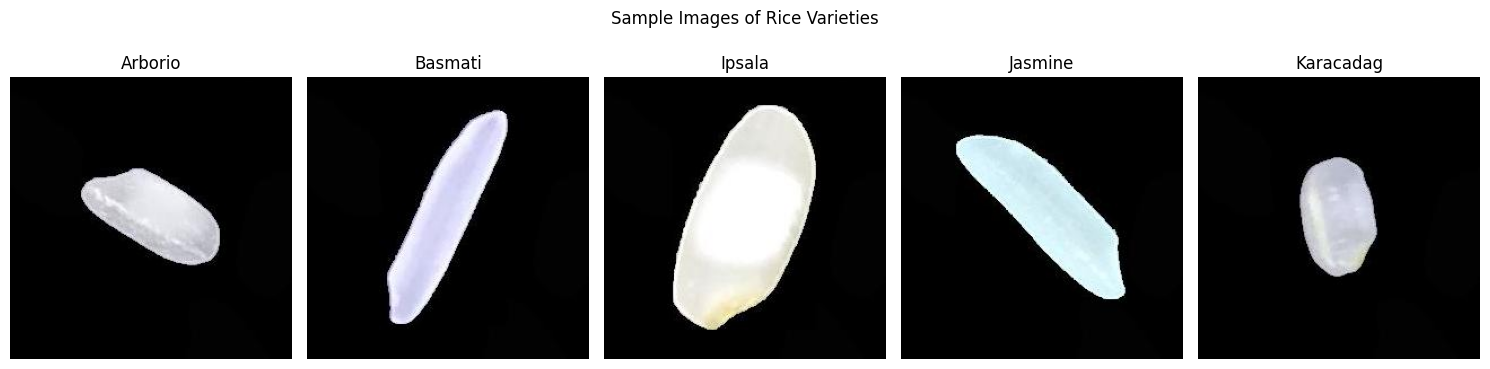

In [12]:
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i, class_name in enumerate(CLASSES):
    image_path = df[df["label"] == class_name].iloc[0]["filepath"]

    with Image.open(image_path) as img:
        axes[i].imshow(img.convert("RGB"))

    axes[i].set_title(class_name)
    axes[i].axis("off")

plt.suptitle("Sample Images of Rice Varieties")
plt.tight_layout()
plt.show()

In [13]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Training images: 1750
Validation images: 375
Testing images: 375


In [14]:
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=15,
    zoom_range=0.10,
    horizontal_flip=True
)

normal_datagen = ImageDataGenerator(
    rescale=1.0 / 255
)

train_gen = train_datagen.flow_from_dataframe(
    train_df,
    x_col="filepath",
    y_col="label",
    classes=CLASSES,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=SEED
)

val_gen = normal_datagen.flow_from_dataframe(
    val_df,
    x_col="filepath",
    y_col="label",
    classes=CLASSES,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

test_gen = normal_datagen.flow_from_dataframe(
    test_df,
    x_col="filepath",
    y_col="label",
    classes=CLASSES,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("Image preprocessing completed!")

Found 1750 validated image filenames belonging to 5 classes.
Found 375 validated image filenames belonging to 5 classes.
Found 375 validated image filenames belonging to 5 classes.
Image preprocessing completed!


In [15]:
model = Sequential([
    tf.keras.Input(shape=(128, 128, 3)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.4),
    Dense(5, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

2026-10-27 07:36:43.620936: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=[early_stop]
)

Epoch 1/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 32s 575ms/step - accuracy: 0.9343 - loss: 0.1798 - val_accuracy: 0.9733 - val_loss: 0.0610
Epoch 2/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 32s 575ms/step - accuracy: 0.9497 - loss: 0.1537 - val_accuracy: 0.9787 - val_loss: 0.0580
Epoch 3/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 32s 581ms/step - accuracy: 0.9343 - loss: 0.1788 - val_accuracy: 0.9707 - val_loss: 0.0831
Epoch 4/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 33s 593ms/step - accuracy: 0.9451 - loss: 0.1751 - val_accuracy: 0.9813 - val_loss: 0.0627
Epoch 5/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 33s 591ms/step - accuracy: 0.9583 - loss: 0.1237 - val_accuracy: 0.9813 - val_loss: 0.0516
Epoch 6/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 41s 596ms/step - accuracy: 0.9320 - loss: 0.1923 - val_accuracy: 0.9733 - val_loss: 0.0650
Epoch 7/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 33s 593ms/step - accuracy: 0.9594 - loss: 0.1086 - val_accuracy: 0.9813 - val_loss: 0.0447
Epoch 8/10
55/55 ━━━━━━━━━━━━━━━━━━━━ 33s 589ms/step - accuracy: 0.9554 - loss: 0.1280 - val_accu

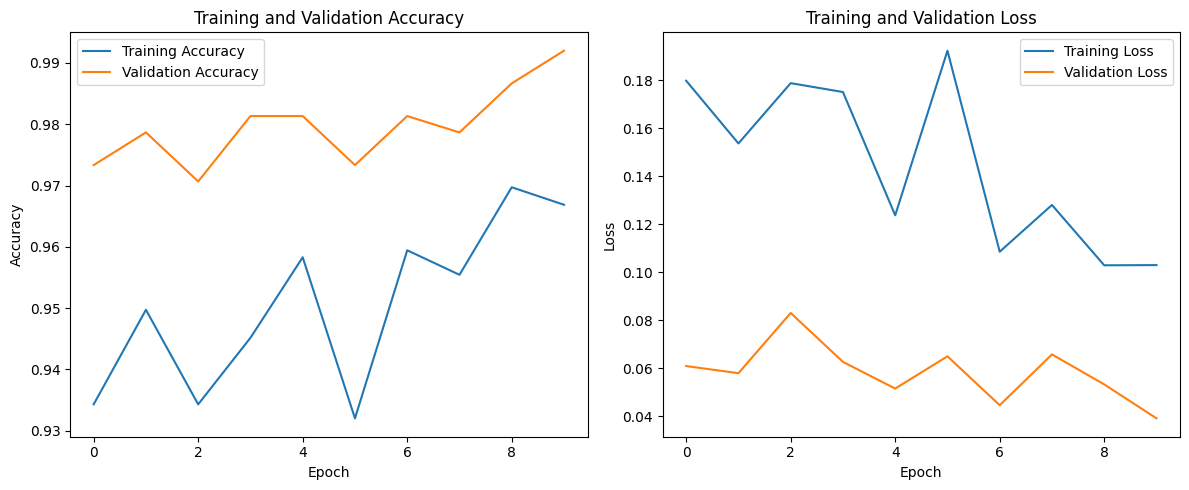

In [23]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [24]:
test_loss, test_accuracy = model.evaluate(test_gen)

probabilities = model.predict(test_gen)
predicted_ids = np.argmax(probabilities, axis=1)
true_ids = test_gen.classes

print("Test loss:", round(test_loss, 4))
print("Test accuracy:", round(test_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    true_ids,
    predicted_ids,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    zero_division=0
))

12/12 ━━━━━━━━━━━━━━━━━━━━ 31s 3s/step - accuracy: 0.9787 - loss: 0.0533
12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 164ms/step
Test loss: 0.0533
Test accuracy: 97.87 %

Classification Report:
              precision    recall  f1-score   support

     Arborio       0.99      0.95      0.97        75
     Basmati       0.99      0.97      0.98        75
      Ipsala       1.00      1.00      1.00        75
     Jasmine       0.95      0.99      0.97        75
   Karacadag       0.97      0.99      0.98        75

    accuracy                           0.98       375
   macro avg       0.98      0.98      0.98       375
weighted avg       0.98      0.98      0.98       375



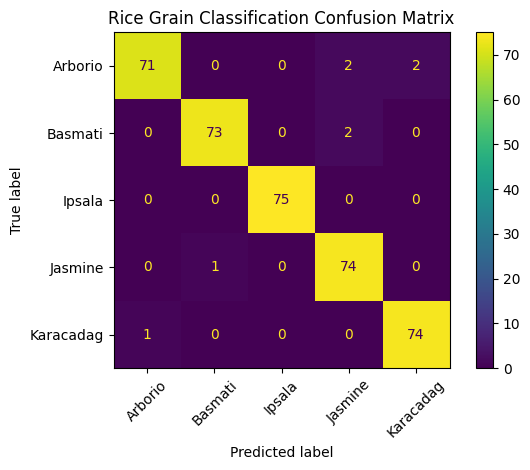

In [25]:
cm = confusion_matrix(
    true_ids,
    predicted_ids,
    labels=list(range(len(CLASSES)))
)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)

cm_display.plot(xticks_rotation=45)
plt.title("Rice Grain Classification Confusion Matrix")
plt.tight_layout()
plt.show()

Actual: Karacadag; Predicted: Arborio. Possible reasons include similar grain shape, texture, colour, or image variation.
Actual: Basmati; Predicted: Jasmine. Possible reasons include similar grain shape, texture, colour, or image variation.
Actual: Arborio; Predicted: Karacadag. Possible reasons include similar grain shape, texture, colour, or image variation.
Actual: Arborio; Predicted: Jasmine. Possible reasons include similar grain shape, texture, colour, or image variation.


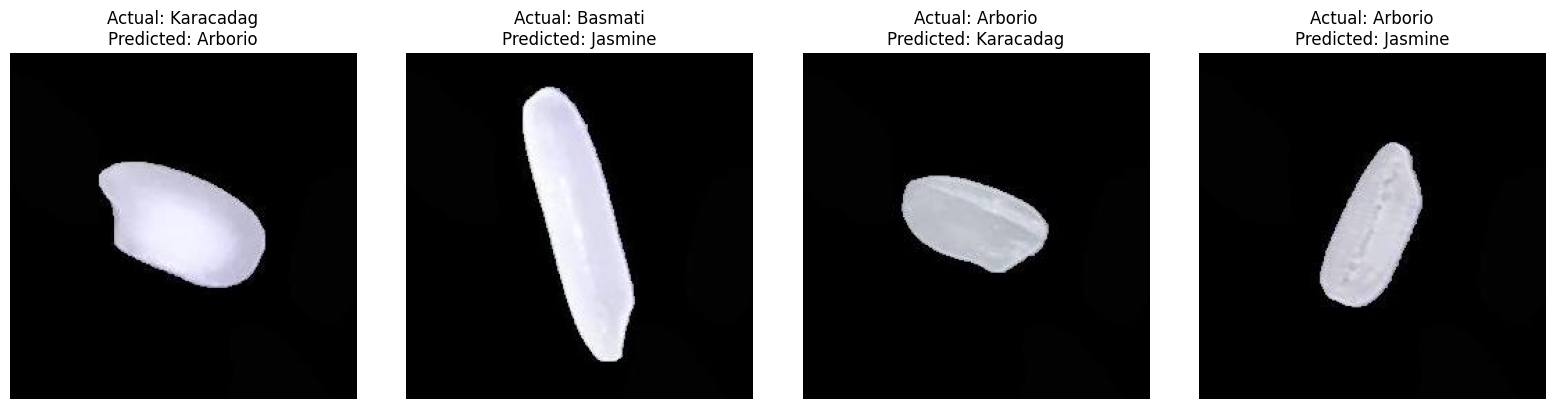

In [26]:
wrong_indices = np.where(predicted_ids != true_ids)[0]
number_to_show = min(4, len(wrong_indices))

if number_to_show == 0:
    print("No misclassified images found in the test subset.")
else:
    fig, axes = plt.subplots(
        1, number_to_show,
        figsize=(4 * number_to_show, 4)
    )

    if number_to_show == 1:
        axes = [axes]

    for ax, idx in zip(axes, wrong_indices[:number_to_show]):
        image_path = test_df.iloc[idx]["filepath"]

        with Image.open(image_path) as img:
            ax.imshow(img.convert("RGB"))

        actual = CLASSES[true_ids[idx]]
        predicted = CLASSES[predicted_ids[idx]]

        ax.set_title(
            f"Actual: {actual}\nPredicted: {predicted}"
        )
        ax.axis("off")

        print(
            f"Actual: {actual}; Predicted: {predicted}. "
            "Possible reasons include similar grain shape, "
            "texture, colour, or image variation."
        )

    plt.tight_layout()
    plt.show()

In [29]:
import os

OUTPUT_DIR = "/kaggle/working/PS11_Rice_Project_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

model.save(
    os.path.join(OUTPUT_DIR, "Rice_Grain_CNN.keras")
)

pd.DataFrame(history.history).to_csv(
    os.path.join(OUTPUT_DIR, "training_history.csv"),
    index=False
)

pd.DataFrame(
    cm,
    index=CLASSES,
    columns=CLASSES
).to_csv(
    os.path.join(OUTPUT_DIR, "confusion_matrix.csv")
)

with open(
    os.path.join(OUTPUT_DIR, "classification_report.txt"),
    "w"
) as f:
    f.write(classification_report(
        true_ids,
        predicted_ids,
        labels=list(range(len(CLASSES))),
        target_names=CLASSES,
        zero_division=0
    ))

print("Model and results saved in:", OUTPUT_DIR)

Model and results saved in: /kaggle/working/PS11_Rice_Project_Results
